# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Лопатін Володимир Дмитрович'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-31'      # напр. 'КН-31'
ВАРІАНТ = 12     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 12 · Лопатін Володимир Дмитрович, ШІ-31, «Друк-Сервіс»
Підприємство «Друк-Сервіс» виготовляє поліграфію. Одиниця виміру плану: тис. прим./тиждень.

                          Буклет  Каталог  Календар  Плакат  ЗАПАС
Крейдований папір, кг          5        2         0       5    788
Офсетний папір, кг             1        1         3       6    661
Фарба, кг                      6        3         5       4    458
Друкарська машина, год         2        4         6       0   1005
Різка й фальцювання, год       4        6         2       4    535

                    Буклет  Каталог  Календар  Плакат
Прибуток з одиниці      39       55        36      26

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Різка й фальцювання, год
  ціна:   5.0 за одиницю
  обсяг:  до 762 одиниць


In [3]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

pulp не встановлено — скористайтеся scipy.optimize.linprog


---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель (варіант 12).** Нехай $x_1,x_2,x_3,x_4$ — випуск буклетів, каталогів, календарів і плакатів відповідно, у тис. примірників за тиждень.

$$\max Z=39x_1+55x_2+36x_3+26x_4.$$

Обмеження:

$$\begin{aligned}
5x_1+2x_2+0x_3+5x_4&\le 788 &&\text{(крейдований папір, кг)},\\
x_1+x_2+3x_3+6x_4&\le 661 &&\text{(офсетний папір, кг)},\\
6x_1+3x_2+5x_3+4x_4&\le 458 &&\text{(фарба, кг)},\\
2x_1+4x_2+6x_3+0x_4&\le 1005 &&\text{(друкарська машина, год)},\\
4x_1+6x_2+2x_3+4x_4&\le 535 &&\text{(різка й фальцювання, год)},\\
x_1,x_2,x_3,x_4&\ge0.
\end{aligned}$$


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2.** Запас $b_i$ заданий до планування: ми обираємо випуск $x_j$, а не кількість ресурсу на складі. Якщо дозволити закупівлю, вводимо додаткову змінну $q_i\ge0$, замінюємо обмеження на $\sum_j a_{ij}x_j\le b_i+q_i$ і віднімаємо витрати $p_iq_i$ з прибутку. Якщо постачання обмежене, також додаємо $q_i\le Q_i$.


---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# План і прибуток перенесено з результату Excel Solver (значення округлено).
EXCEL_ПЛАН = [0.0, 73.2917, 47.625, 0.0]
EXCEL_ПРИБУТОК = 5745.5417
print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)


Excel: [0.0, 73.2917, 47.625, 0.0] | прибуток 5745.5417


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
# Для max c·x функція linprog мінімізує -c·x.
розвязок = linprog(-c, A_ub=A, b_ub=b, bounds=(0, None), method='highs')
assert розвязок.success, розвязок.message
план = розвязок.x
прибуток = -розвязок.fun
print(pd.Series(план, index=вироби, name='Випуск'))
print(f'Максимальний прибуток: {прибуток:.6f}')


Буклет       0.000000
Каталог     73.291667
Календар    47.625000
Плакат       0.000000
Name: Випуск, dtype: float64
Максимальний прибуток: 5745.541667


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5)
print('Результати Excel Solver і Python збігаються в межах допуску.')


Результати Excel Solver і Python збігаються в межах допуску.


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

**Відповідь 4.1 — блок «Обмеження».** Числа перенесено зі звіту про стійкість Excel Solver і звірено з незалежним розрахунком Python; невеликі відмінності спричинені округленням.

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---:|---:|---:|---:|---:|
| Крейдований папір, кг | 146,5833 | 0 | 788 | ∞ | 641,4167 |
| Офсетний папір, кг | 216,1667 | 0 | 661 | ∞ | 444,8333 |
| Фарба, кг | 458 | 4,4167 | 458 | 365,2143 | 190,5 |
| Друкарська машина, год | 578,9167 | 0 | 1005 | ∞ | 426,0833 |
| Різка й фальцювання, год | 535 | 6,9583 | 535 | 381 | 351,8 |

**Дефіцитні ресурси:** фарба та різка з фальцюванням: їх витрачено повністю, і тіньові ціни додатні. Решта мають залишок та нульову тіньову ціну. $\infty$ означає відсутність скінченної межі в цій лінійній моделі.


### Завдання 4.2 — блок «Змінні»

**Відповідь 4.2 — блок «Змінні».** Числа перенесено зі звіту про стійкість Excel Solver і звірено з Python. Зведена вартість має знак для задачі *максимізації*.

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---:|---:|---:|---:|---:|
| Буклет | 0 | −15,3333 | 39 | 15,3333 | ∞ |
| Каталог | 73,2917 | 0 | 55 | 53 | 33,4 |
| Календар | 47,625 | 0 | 36 | 55,6667 | 15,3333 |
| Плакат | 0 | −19,5 | 26 | 19,5 | ∞ |

Буклет і плакат не виробляються. Щоб виріб **міг** увійти в оптимальний план, прибуток з його одиниці має зрости щонайменше на модуль зведеної вартості: для буклета на 15,3333, для плаката на 19,5. На самій межі можливе альтернативне оптимальне рішення; для гарантованого входження потрібне більше зростання.


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
# Числа з блоку «Обмеження» звіту Excel Solver (за порядком ресурсів у V).
тіньові_ціни_excel = np.array([0, 0, 4.416666667, 0, 6.958333333], dtype=float)
допустимі_збільшення_excel = np.array([np.inf, np.inf, 365.2142857, np.inf, 381.0])
індекс_ресурсу = int(np.argmax(тіньові_ціни_excel))
тіньова_ціна = float(тіньові_ціни_excel[індекс_ресурсу])
тіньова_ціна_python = float(-розвязок.ineqlin.marginals[індекс_ресурсу])
assert np.isclose(тіньова_ціна_python, тіньова_ціна)
b_плюс_1 = b.copy()
b_плюс_1[індекс_ресурсу] += 1
розвязок_плюс_1 = linprog(-c, A_ub=A, b_ub=b_плюс_1, bounds=(0, None), method='highs')
assert розвязок_плюс_1.success
приріст_1 = -розвязок_плюс_1.fun - прибуток
print(ресурси[індекс_ресурсу],
      'приріст прибутку:', f'{приріст_1:.6f}',
      'тіньова ціна Excel:', f'{тіньова_ціна:.6f}',
      'тіньова ціна Python:', f'{тіньова_ціна_python:.6f}')
assert np.isclose(приріст_1, тіньова_ціна)


Різка й фальцювання, год приріст прибутку: 6.958333 тіньова ціна Excel: 6.958333 тіньова ціна Python: 6.958333


**Відповідь 5.1.** Найцінніший ресурс — різка й фальцювання. Після збільшення запасу з 535 до 536 год прибуток зростає на **6,9583**, що збігається з тіньовою ціною **6,9583** за годину зі звіту Excel Solver.


### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

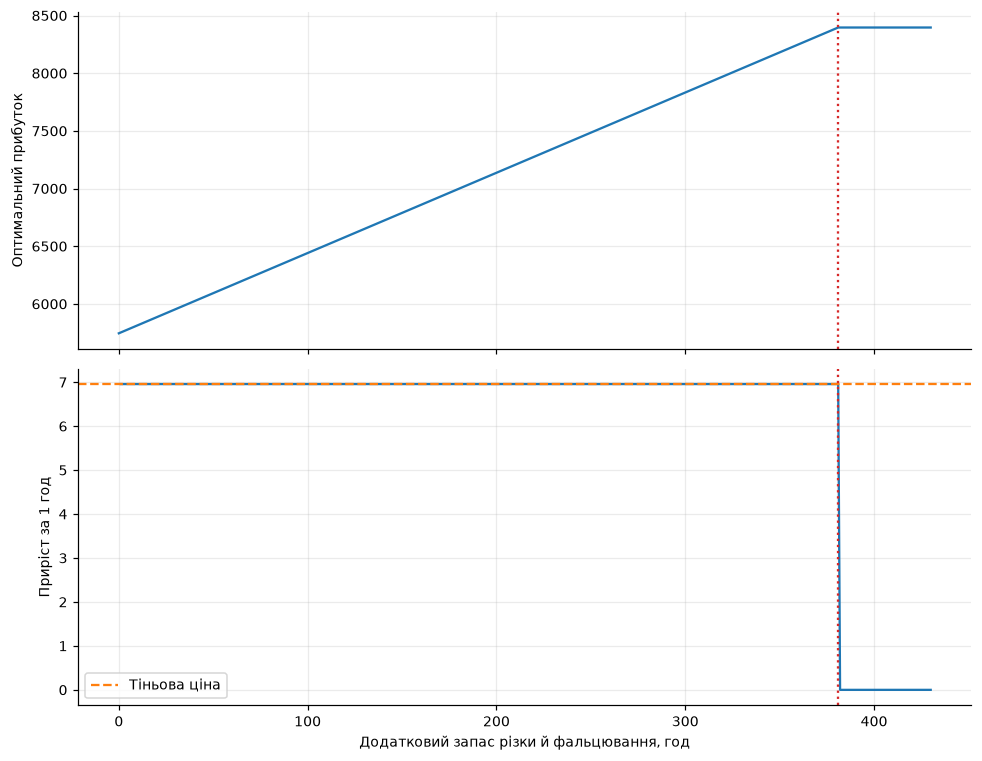

Межа за експериментом: 381 | допустиме збільшення Excel: 381


In [8]:
межа_excel = int(допустимі_збільшення_excel[індекс_ресурсу])
додаткові_години = np.arange(0, межа_excel + 50, 1)
прибутки_експерименту = []
for delta in додаткові_години:
    новий_b = b.copy()
    новий_b[індекс_ресурсу] += delta
    result = linprog(-c, A_ub=A, b_ub=новий_b, bounds=(0, None), method='highs')
    assert result.success, result.message
    прибутки_експерименту.append(-result.fun)
прирости_експерименту = np.diff(прибутки_експерименту)
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(додаткові_години, прибутки_експерименту)
axes[0].set_ylabel('Оптимальний прибуток')
axes[1].plot(додаткові_години[1:], прирости_експерименту)
axes[1].axhline(тіньова_ціна, color='tab:orange', linestyle='--', label='Тіньова ціна')
axes[1].set_ylabel('Приріст за 1 год')
axes[1].set_xlabel('Додатковий запас різки й фальцювання, год')
axes[1].legend()
for ax in axes:
    ax.axvline(межа_excel, color='tab:red', linestyle=':', label=f'Межа Excel: {межа_excel} год')
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
межа_експерименту = int(np.where(np.isclose(прирости_експерименту, тіньова_ціна, atol=1e-7))[0].max() + 1)
print('Межа за експериментом:', межа_експерименту, '| допустиме збільшення Excel:', межа_excel)
assert межа_експерименту == межа_excel


**Відповідь 5.2.** Початкова тіньова ціна зберігається до додаткових **381 год** включно. Від 382-ї години граничний приріст падає до нуля: фарба стає єдиним обмежувальним ресурсом. Отримана межа збігається з допустимим збільшенням **381 год** у звіті Excel Solver.


---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [9]:
ціна_закупівлі = float(V['ціна_пропозиції'])
ліміт_постачальника = int(V['обсяг_пропозиції'])
індекс_пропозиції = int(V['ресурс_пропозиції'])
assert індекс_пропозиції == індекс_ресурсу
# Одна спільна LP-модель обирає випуск x та обсяг закупівлі q.
матриця_закупівлі = np.column_stack([A, -np.eye(len(b))[:, індекс_пропозиції]])
закупівля_LP = linprog(-np.r_[c, -ціна_закупівлі], A_ub=матриця_закупівлі,
                      b_ub=b, bounds=[(0, None)] * len(c) + [(0, ліміт_постачальника)],
                      method='highs')
assert закупівля_LP.success
купити = float(закупівля_LP.x[-1])
новий_запас = b.copy()
новий_запас[індекс_пропозиції] += купити
перевірка_закупівлі = linprog(-c, A_ub=A, b_ub=новий_запас,
                             bounds=(0, None), method='highs')
assert перевірка_закупівлі.success
валовий_приріст = -перевірка_закупівлі.fun - прибуток
чистий_виграш = валовий_приріст - ціна_закупівлі * купити
assert np.isclose(чистий_виграш, -закупівля_LP.fun - прибуток)
print(f'Купити {купити:.3f} год; валовий приріст {валовий_приріст:.3f}; '
      f'витрати {ціна_закупівлі * купити:.3f}; чистий виграш {чистий_виграш:.3f}')


Купити 381.000 год; валовий приріст 2651.125; витрати 1905.000; чистий виграш 746.125


**Відповідь 6.1.** Брати: перша додаткова година приносить **6,9583** за тіньовою ціною звіту Excel Solver, а коштує **5**. Купити **381 год** із запропонованих 762: на 382-й годині додаткова різка вже не підвищує прибуток, тому її купівля дала б збиток. Новий максимум до витрат на закупівлю — **8396,6667**; валовий приріст — **2651,125**; витрати — **1905**; чистий виграш — **746,125**. Прямий повторний розв'язок із запасом 916 год підтвердив ці числа.


---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
ненульових = int(np.count_nonzero(план > 1e-7))
використано = A @ план
звязних = int(np.count_nonzero(np.isclose(використано, b, atol=1e-7)))
print('Ненульових виробів:', ненульових, 'зв’язних ресурсних обмежень:', звязних)


Ненульових виробів: 2 зв’язних ресурсних обмежень: 2


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1.** Є **2** ненульові види продукції та **2** зв'язні ресурсні обмеження. Цей збіг характерний для цього невиродженого оптимального базису, але не є загальним законом лінійного програмування. Розбіжність вимагала б перевірити виродженість, надлишкові обмеження або числовий допуск; сама по собі вона ще не доводила б помилки.


---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
округлений = np.floor(план + 0.5).astype(int)
витрати_округленого = A @ округлений
допустимий_округлений = bool(np.all(витрати_округленого <= b + 1e-8))
цілий_розвязок = linprog(-c, A_ub=A, b_ub=b, bounds=(0, None),
                        integrality=np.ones(len(c)), method='highs')
assert цілий_розвязок.success
цілий_план = np.rint(цілий_розвязок.x).astype(int)
print('Дробовий план:', план, 'прибуток:', прибуток)
print('Округлений:', округлений, 'прибуток:', c @ округлений,
      'допустимий:', допустимий_округлений, 'витрати:', витрати_округленого)
print('Цілочисельний оптимум:', цілий_план, 'прибуток:', -цілий_розвязок.fun)


Дробовий план: [ 0.         73.29166667 47.625       0.        ] прибуток: 5745.541666666667
Округлений: [ 0 73 48  0] прибуток: 5743.0 допустимий: False витрати: [146. 217. 459. 580. 534.]
Цілочисельний оптимум: [ 1 73 46  0] прибуток: 5710.0


**Відповідь 8.1.** Порядок компонентів: буклет, каталог, календар, плакат.

| Варіант | План | Прибуток | Допустимий? |
|---|---|---:|---|
| Без цілочисельності | (0; 73,2917; 47,625; 0) | 5745,5417 | Так, для неперервної моделі |
| Округлений | (0; 73; 48; 0) | 5743 | **Ні**: потрібно 459 кг фарби при запасі 458 кг |
| Цілочисельний оптимум | (1; 73; 46; 0) | 5710 | Так |

**Висновок:** просте округлення порушує обмеження й не гарантує максимум; потрібне окреме цілочисельне розв'язання.


---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [13]:
# Л/О/П із прізвища Лопатін; В/О/Л/О з імені Володимир.
постачальники = ['Львів', 'Одеса', 'Полтава']
споживачі = ['Вінниця', 'Охтирка', 'Луцьк', 'Олександрія']
# Кілометри швидкого автодорожнього маршруту Flagma; джерела наведені нижче.
D = np.array([[369, 899, 150, 781],
              [422, 679, 790, 410],
              [619, 100, 772, 168]], dtype=float)
запас = [18, 22, 20]
попит = [12, 16, 14, 18]
assert len(постачальники) == 3 and len(споживачі) == 4
assert D.shape == (3, 4)
assert sum(запас) == sum(попит) == 60
display(pd.DataFrame(D.astype(int), index=постачальники, columns=споживачі))


,Вінниця,Охтирка,Луцьк,Олександрія
Львів,369,899,150,781
Одеса,422,679,790,410
Полтава,619,100,772,168


**Джерела матриці відстаней.** Наразі використано відстані швидких автомобільних маршрутів [Flagma](https://flagma.ua/uk/vidstan-vid-lvov-do.html):

| Початок | Вінниця | Охтирка | Луцьк | Олександрія |
|---|---|---|---|---|
| Львів | [369](https://flagma.ua/uk/vidstan-lvov-vinnica/) | [899](https://flagma.ua/uk/vidstan-lvov-ahtyrka/) | [150](https://flagma.ua/uk/vidstan-lvov-luck/) | [781](https://flagma.ua/uk/vidstan-lvov-aleksandriyaukr/) |
| Одеса | [422](https://flagma.ua/uk/vidstan-odessa-vinnica/) | [679](https://flagma.ua/uk/vidstan-odessa-ahtyrka/) | [790](https://flagma.ua/uk/vidstan-odessa-luck/) | [410](https://flagma.ua/uk/vidstan-odessa-aleksandriyaukr/) |
| Полтава | [619](https://flagma.ua/uk/vidstan-poltava-vinnica/) | [100](https://flagma.ua/uk/vidstan-poltava-ahtyrka/) | [772](https://flagma.ua/uk/vidstan-poltava-luck/) | [168](https://flagma.ua/uk/vidstan-poltava-aleksandriyaukr/) |

**Перед здачею:** методичка вимагає саме Google Maps. Поточні 12 чисел треба звірити з вибраними автомобільними маршрутами Google Maps; після заміни матриці `D` всі нижчі розрахунки перерахуються.

---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [14]:
# Спосіб 1: scipy.optimize.linprog (HiGHS), усі 7 обмежень задано рівностями.
матриця_рівностей = np.zeros((7, 12))
for i in range(3):
    for j in range(4):
        матриця_рівностей[i, 4*i+j] = 1
        матриця_рівностей[3+j, 4*i+j] = 1
транспорт_scipy = linprog(D.ravel(), A_eq=матриця_рівностей,
                         b_eq=np.r_[запас, попит], bounds=(0, None), method='highs')
assert транспорт_scipy.success, транспорт_scipy.message
план_scipy = транспорт_scipy.x.reshape(3, 4)
ціна_scipy = транспорт_scipy.fun
дуальні_scipy = транспорт_scipy.eqlin.marginals
print('SciPy, вартість:', ціна_scipy)
display(pd.DataFrame(план_scipy, index=постачальники, columns=споживачі))
display(pd.Series(дуальні_scipy, index=постачальники+споживачі, name='Тіньові ціни SciPy'))


SciPy, вартість: 14964.0


,Вінниця,Охтирка,Луцьк,Олександрія
Львів,4.0,0.0,14.0,0.0
Одеса,8.0,0.0,0.0,14.0
Полтава,0.0,16.0,0.0,4.0


Львів           -0.0
Одеса           53.0
Полтава       -189.0
Вінниця        369.0
Охтирка        289.0
Луцьк          150.0
Олександрія    357.0
Name: Тіньові ціни SciPy, dtype: float64

In [15]:
# Спосіб 2: NetworkX min_cost_flow. Дуальні оцінки відновлено з умов
# u_i + v_j = d_ij на зайнятих маршрутах; фіксуємо довільне u_0=1.
import networkx as nx
мережа = nx.DiGraph()
for i, amount in enumerate(запас):
    мережа.add_node(f's{i}', demand=-int(amount))
for j, amount in enumerate(попит):
    мережа.add_node(f'd{j}', demand=int(amount))
for i in range(3):
    for j in range(4):
        мережа.add_edge(f's{i}', f'd{j}', capacity=int(запас[i]), weight=int(D[i,j]))
потік = nx.min_cost_flow(мережа)
план_nx = np.array([[потік[f's{i}'][f'd{j}'] for j in range(4)] for i in range(3)])
ціна_nx = float(np.sum(D * план_nx))
активні = np.argwhere(план_nx > 0)
система = np.zeros((len(активні)+1, 7))
права_частина = np.zeros(len(активні)+1)
for k, (i, j) in enumerate(активні):
    система[k, i] = 1
    система[k, 3+j] = 1
    права_частина[k] = D[i,j]
система[-1, 0] = 1
права_частина[-1] = 1
дуальні_nx = np.linalg.solve(система, права_частина)
assert np.all(дуальні_nx[:3, None] + дуальні_nx[3:] <= D + 1e-7)
print('NetworkX, вартість:', ціна_nx)
display(pd.DataFrame(план_nx, index=постачальники, columns=споживачі))
display(pd.Series(дуальні_nx, index=постачальники+споживачі, name='Тіньові ціни NetworkX'))


NetworkX, вартість: 14964.0


,Вінниця,Охтирка,Луцьк,Олександрія
Львів,4,0,14,0
Одеса,8,0,0,14
Полтава,0,16,0,4


Львів            1.0
Одеса           54.0
Полтава       -188.0
Вінниця        368.0
Охтирка        288.0
Луцьк          149.0
Олександрія    356.0
Name: Тіньові ціни NetworkX, dtype: float64

### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [16]:
assert np.isclose(ціна_scipy, ціна_nx)
assert np.allclose(план_scipy, план_nx)
різниця_дуальних = дуальні_nx - дуальні_scipy
display(pd.DataFrame({'SciPy': дуальні_scipy, 'NetworkX': дуальні_nx,
                      'Різниця': різниця_дуальних}, index=постачальники+споживачі))
assert np.allclose(різниця_дуальних[:3], 1)
assert np.allclose(різниця_дуальних[3:], -1)


,SciPy,NetworkX,Різниця
Львів,-0.0,1.0,1.0
Одеса,53.0,54.0,1.0
Полтава,-189.0,-188.0,1.0
Вінниця,369.0,368.0,-1.0
Охтирка,289.0,288.0,-1.0
Луцьк,150.0,149.0,-1.0
Олександрія,357.0,356.0,-1.0


**Відповідь 10.2.** Обидва способи дають план із **6** зайнятими маршрутами та вартість **14964 км·од.** Оцінки NetworkX, отримані з його плану за нормування $u_{Львів}=1$, на **1** більші за SciPy для кожного постачальника й на **1** менші для кожного споживача. Через баланс $\sum s_i=\sum d_j$ одна рівність надлишкова: перетворення $u_i\mapsto u_i+t$, $v_j\mapsto v_j-t$ не змінює ні $u_i+v_j$, ні загальну вартість. Тому окрема тіньова ціна рівності не має однозначного змісту без указання нормування та узгодженої зміни запасу й попиту.


---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [17]:
ненульових_перевезень = int(np.count_nonzero(план_scipy > 1e-7))
звязних_транспортних = (int(np.count_nonzero(np.isclose(план_scipy.sum(axis=1), запас)))
                         + int(np.count_nonzero(np.isclose(план_scipy.sum(axis=0), попит))))
print('Ненульових перевезень:', ненульових_перевезень)
print('Зв’язних рівностей:', звязних_транспортних)
print('Ранг матриці рівностей:', np.linalg.matrix_rank(матриця_рівностей))


Ненульових перевезень: 6
Зв’язних рівностей: 7
Ранг матриці рівностей: 6


**Відповідь 11.1.** Ненульових перевезень **6**, зв'язних обмежень **7**. Усі сім рівностей виконуються точно за постановкою. Одна з них залежна від інших, бо загальний запас дорівнює загальному попиту; ранг матриці — **6**. Тому невироджений базис транспортної задачі $3	imes4$ має $3+4-1=6$ зайнятих маршрутів — на один менше за кількість записаних рівностей.


### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

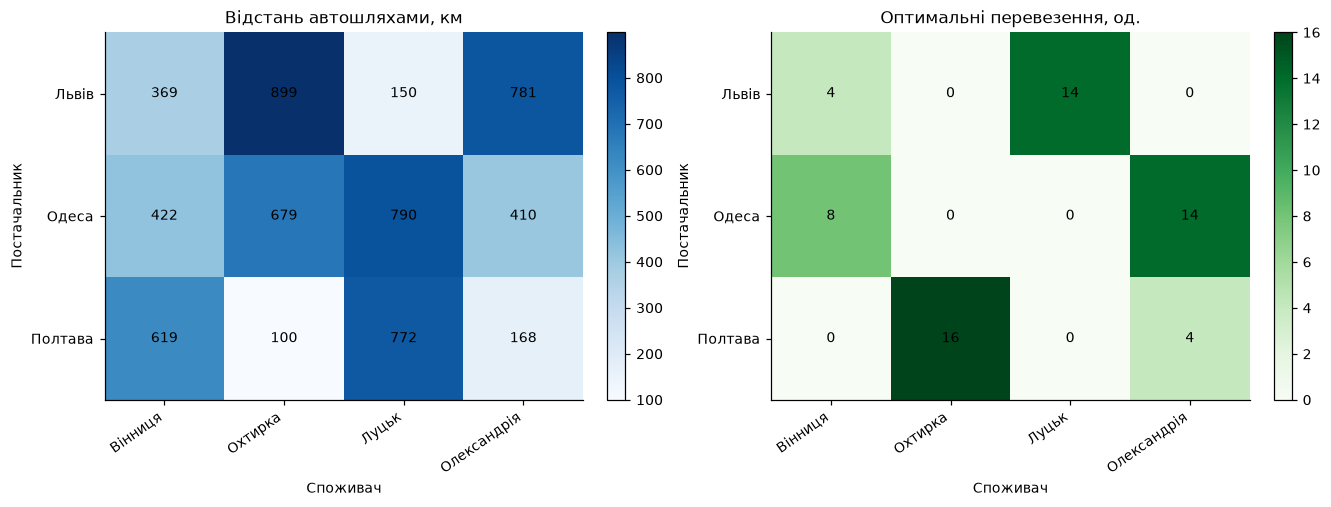

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, matrix, title, cmap in zip(axes, [D, план_scipy],
                                   ['Відстань автошляхами, км', 'Оптимальні перевезення, од.'],
                                   ['Blues', 'Greens']):
    im = ax.imshow(matrix, cmap=cmap, aspect='auto')
    ax.set_xticks(range(4), споживачі, rotation=35, ha='right')
    ax.set_yticks(range(3), постачальники)
    ax.set_xlabel('Споживач')
    ax.set_ylabel('Постачальник')
    ax.set_title(title)
    for i in range(3):
        for j in range(4):
            ax.text(j, i, f'{matrix[i,j]:.0f}', ha='center', va='center', color='black')
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()


**Висновок.** План використовує переважно коротші маршрути, але потреба збалансувати запаси й попит залишає, зокрема, 14 одиниць на маршруті Одеса → Олександрія та 4 одиниці Львів → Вінниця; локально найдешевший вибір для кожного міста окремо не гарантує спільного оптимуму.


---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [ ]:
ІНСТРУМЕНТИ_ШІ = 'OpenAI Codex'
ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі': 'текст, як є',
    'етап 2, побудова моделі в Excel': 'код, перевірено',
    'етап 3, код на Python': 'код, перевірено',
    'етапи 4–5, читання та перевірка звіту': 'код, перевірено',
    'етап 6, рішення про закупівлю': 'код, перевірено',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача': 'код, перевірено',
}
ЩО_ПЕРЕВІРЕНО = (
    'Агент звірив дані варіанта 12, прямим множенням A@x перевірив запаси, '
    'повторним розв’язанням — тіньову ціну й закупівлю, окремою MILP — цілочисельний план, '
    'а для транспорту — баланс, вартість і двоїсту допустимість. '
    'Перед захистом студент має особисто повторити ці перевірки, звірити відстані у Google Maps '
    'та нативний звіт Excel Solver, а також пояснити кожен рядок коду.'
)
# Особисте підтвердження може надати тільки студент після розбору всіх клітинок.
ПІДТВЕРДЖУЮ = False


In [ ]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

---
# Крок 13. Фінальна самоперевірка

In [ ]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')